Importing Libraries:

In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.impute import SimpleImputer


Loading and Previewing Dataset:

In [125]:
data = pd.read_csv("heart_modified.csv")

Display first few rows:

In [126]:
print("Dataset preview:")
data.head()

Dataset preview:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40.0,M,ATA,140.0,289.0,0.0,Normal,172.0,N,0.0,Up,0
1,49.0,F,NAP,160.0,180.0,0.0,Normal,156.0,N,1.0,Flat,1
2,37.0,M,ATA,130.0,283.0,0.0,ST,98.0,N,0.0,Up,0
3,48.0,F,ASY,138.0,214.0,0.0,Normal,108.0,Y,1.5,Flat,1
4,54.0,M,NAP,150.0,195.0,0.0,Normal,122.0,N,0.0,Up,0


Check sum of null values before handling:

In [127]:
print("\nNull values before handling:")
data.isnull().sum()


Null values before handling:


Age               50
Sex               42
ChestPainType     35
RestingBP         48
Cholesterol       30
FastingBS         61
RestingECG        46
MaxHR             15
ExerciseAngina    56
Oldpeak           22
ST_Slope          57
HeartDisease       0
dtype: int64

Separate numeric and categorical columns:

In [128]:
numeric_cols = data.select_dtypes(include=['int64', 'float64']).columns
categorical_cols = data.select_dtypes(include=['object']).columns

Imputers:

In [129]:
num_imputer = SimpleImputer(strategy='mean')
cat_imputer = SimpleImputer(strategy='most_frequent')

data[numeric_cols] = num_imputer.fit_transform(data[numeric_cols])
data[categorical_cols] = cat_imputer.fit_transform(data[categorical_cols])

Check sum of null values after handling:

In [130]:
print("\nNull values after handling:")
data.isnull().sum()


Null values after handling:


Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

One-Hot Encode categorical features:

In [131]:
data = pd.get_dummies(data, drop_first=True)

Prepare features and target:

In [132]:
X = data.drop(columns=['HeartDisease']).values
y = data['HeartDisease'].values

Train-test split:

In [133]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

Scale features:

In [134]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Applying KNN:

In [135]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_test_scaled)
knn_score = accuracy_score(y_test, y_pred_knn)

print(f"\nKNN Accuracy: {knn_score:.2f}")
print("\nConfusion Matrix - KNN:")
print(confusion_matrix(y_test, y_pred_knn))


KNN Accuracy: 0.86

Confusion Matrix - KNN:
[[68 11]
 [15 90]]


Applying Naive Bayes:

In [136]:
nb = GaussianNB()
nb.fit(X_train_scaled, y_train)
y_pred_nb = nb.predict(X_test_scaled)
nb_score = accuracy_score(y_test, y_pred_nb)

print(f"\nNaive Bayes Accuracy: {nb_score:.2f}")
print("\nConfusion Matrix - Naive Bayes:")
print(confusion_matrix(y_test, y_pred_nb))



Naive Bayes Accuracy: 0.85

Confusion Matrix - Naive Bayes:
[[67 12]
 [16 89]]


TABLE: Actual vs Predicted:

In [137]:

comparison = pd.DataFrame({
    'Actual': y_test,
    'Predicted_KNN': y_pred_knn,
    'Predicted_NB': y_pred_nb
})

comparison['KNN_Correct'] = comparison['Actual'] == comparison['Predicted_KNN']
comparison['NB_Correct'] = comparison['Actual'] == comparison['Predicted_NB']

print("\nWith Correct/Incorrect Flags:")
comparison.head(20)





With Correct/Incorrect Flags:


,Actual,Predicted_KNN,Predicted_NB,KNN_Correct,NB_Correct
0,1.0,1.0,1.0,True,True
1,1.0,1.0,1.0,True,True
2,0.0,0.0,0.0,True,True
3,0.0,0.0,0.0,True,True
4,1.0,1.0,1.0,True,True
5,0.0,0.0,0.0,True,True
6,0.0,0.0,0.0,True,True
7,1.0,1.0,1.0,True,True
8,1.0,1.0,1.0,True,True
9,0.0,0.0,0.0,True,True


Donut Chart for Correct Prediction:

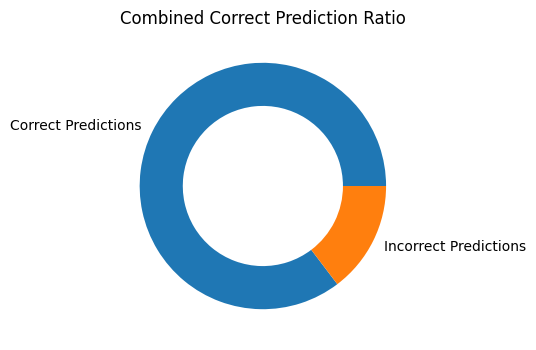

KNN Correct %: 85.9%
Naive Bayes Correct %: 84.8%


In [138]:

knn_correct = comparison["KNN_Correct"].mean()
nb_correct = comparison["NB_Correct"].mean()

plt.figure(figsize=(4,4))
plt.pie(
    [knn_correct + nb_correct, 2 - (knn_correct + nb_correct)],
    labels=["Correct Predictions", "Incorrect Predictions"],
    wedgeprops={"width": 0.35}
)
plt.title("Combined Correct Prediction Ratio")
plt.show()

print(f"KNN Correct %: {knn_correct*100:.1f}%")
print(f"Naive Bayes Correct %: {nb_correct*100:.1f}%")



-- KNN can model non-linear class boundaries based on local neighborhoods, which suits the dataset’s complex medical patterns better than NB’s simpler probability      surfaces.

-- KNN showed higher empirical accuracy (~86% vs ~84%), meaning fewer overall misclassifications compared to NB on this dataset.

KNN performs better on this dataset

More accurate by ~2%